# Parkinson's Prediction with 8 less Features

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost

In [2]:
print(xgboost.__version__)

1.7.4


In [3]:
features = ["MDVP:Fo(Hz)","MDVP:Fhi(Hz)","MDVP:Flo(Hz)","MDVP:Jitter(%)","MDVP:Jitter(Abs)","MDVP:RAP","MDVP:PPQ","Jitter:DDP","MDVP:Shimmer","MDVP:Shimmer(dB)","Shimmer:APQ3","Shimmer:APQ5","MDVP:APQ","Shimmer:DDA","NHR","HNR","RPDE","DFA","spread1","spread2","D2","PPE","status"]


In [4]:
len(features)

23

In [5]:
pd.set_option('display.max_columns', None)
pd.set_option('max_colwidth', None)

In [6]:
columns_to_drop = ["MDVP:PPQ","MDVP:APQ","RPDE","DFA","spread1","spread2","D2","PPE"]

In [7]:
dataset = pd.read_csv ('parkinsons.csv', index_col=['name']) 

dataset.head()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,MDVP:APQ,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
name,,,,,,,,,,,,,,,,,,,,,,,
phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,0.426,0.02182,0.03130,0.02971,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,0.626,0.03134,0.04518,0.04368,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.482,0.02757,0.03858,0.03590,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,0.517,0.02924,0.04005,0.03772,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,0.584,0.03490,0.04825,0.04465,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [8]:
dataset.drop(columns_to_drop, axis=1, inplace=True)

dataset.head()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:DDA,NHR,HNR,status
name,,,,,,,,,,,,,,,
phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.01109,0.04374,0.426,0.02182,0.03130,0.06545,0.02211,21.033,1
phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.01394,0.06134,0.626,0.03134,0.04518,0.09403,0.01929,19.085,1
phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.01633,0.05233,0.482,0.02757,0.03858,0.08270,0.01309,20.651,1
phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.01505,0.05492,0.517,0.02924,0.04005,0.08771,0.01353,20.644,1
phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.01966,0.06425,0.584,0.03490,0.04825,0.10470,0.01767,19.649,1


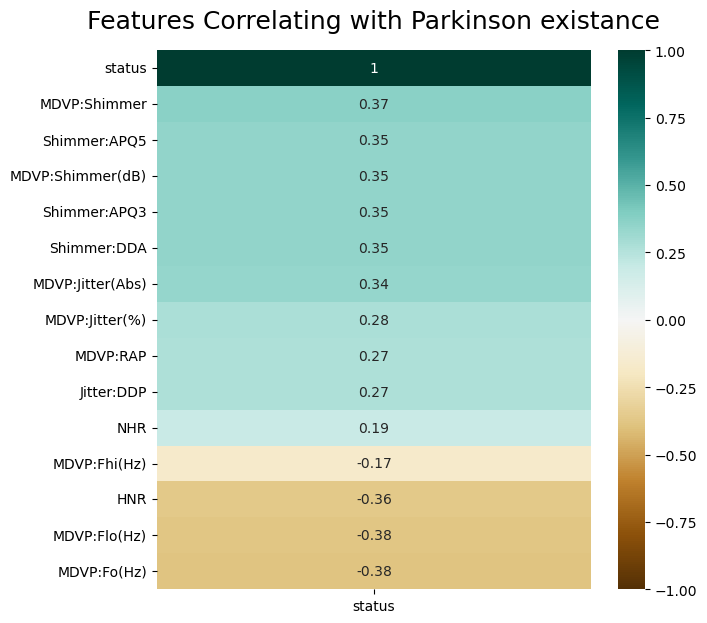

In [10]:
# modify the headmap plot to show correlation variables to the status 
plt.figure(figsize=(7, 7))
heatmap = sns.heatmap(dataset.corr()[['status']].sort_values(by='status', ascending=False), vmin=-1, vmax=1, annot=True, cmap='BrBG')
heatmap.set_title('Features Correlating with Parkinson existance', fontdict={'fontsize':18}, pad=16);

In [11]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 195 entries, phon_R01_S01_1 to phon_R01_S50_6
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MDVP:Fo(Hz)       195 non-null    float64
 1   MDVP:Fhi(Hz)      195 non-null    float64
 2   MDVP:Flo(Hz)      195 non-null    float64
 3   MDVP:Jitter(%)    195 non-null    float64
 4   MDVP:Jitter(Abs)  195 non-null    float64
 5   MDVP:RAP          195 non-null    float64
 6   Jitter:DDP        195 non-null    float64
 7   MDVP:Shimmer      195 non-null    float64
 8   MDVP:Shimmer(dB)  195 non-null    float64
 9   Shimmer:APQ3      195 non-null    float64
 10  Shimmer:APQ5      195 non-null    float64
 11  Shimmer:DDA       195 non-null    float64
 12  NHR               195 non-null    float64
 13  HNR               195 non-null    float64
 14  status            195 non-null    int64  
dtypes: float64(14), int64(1)
memory usage: 24.4+ KB


In [12]:
len(dataset)

195

### Boxplot of training data (dataset)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14]),
 [Text(0, 0, 'MDVP:Fo(Hz)'),
  Text(1, 0, 'MDVP:Fhi(Hz)'),
  Text(2, 0, 'MDVP:Flo(Hz)'),
  Text(3, 0, 'MDVP:Jitter(%)'),
  Text(4, 0, 'MDVP:Jitter(Abs)'),
  Text(5, 0, 'MDVP:RAP'),
  Text(6, 0, 'Jitter:DDP'),
  Text(7, 0, 'MDVP:Shimmer'),
  Text(8, 0, 'MDVP:Shimmer(dB)'),
  Text(9, 0, 'Shimmer:APQ3'),
  Text(10, 0, 'Shimmer:APQ5'),
  Text(11, 0, 'Shimmer:DDA'),
  Text(12, 0, 'NHR'),
  Text(13, 0, 'HNR'),
  Text(14, 0, 'status')])

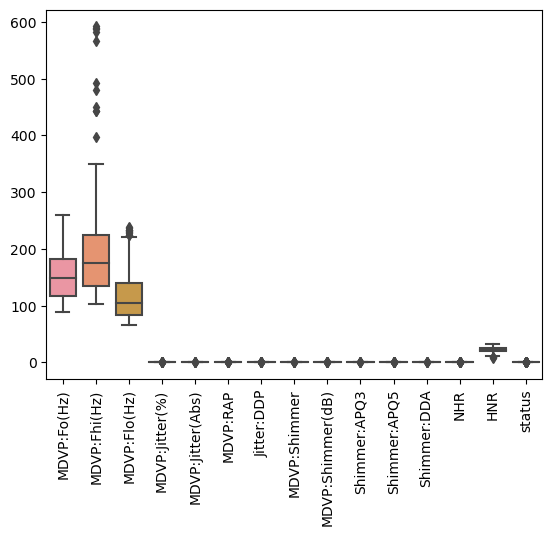

In [13]:
sns.boxplot(data=dataset)
plt.xticks(rotation=90)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14]),
 [Text(0, 0, 'MDVP:Fo(Hz)'),
  Text(1, 0, 'MDVP:Fhi(Hz)'),
  Text(2, 0, 'MDVP:Flo(Hz)'),
  Text(3, 0, 'MDVP:Jitter(%)'),
  Text(4, 0, 'MDVP:Jitter(Abs)'),
  Text(5, 0, 'MDVP:RAP'),
  Text(6, 0, 'Jitter:DDP'),
  Text(7, 0, 'MDVP:Shimmer'),
  Text(8, 0, 'MDVP:Shimmer(dB)'),
  Text(9, 0, 'Shimmer:APQ3'),
  Text(10, 0, 'Shimmer:APQ5'),
  Text(11, 0, 'Shimmer:DDA'),
  Text(12, 0, 'NHR'),
  Text(13, 0, 'HNR'),
  Text(14, 0, 'status')])

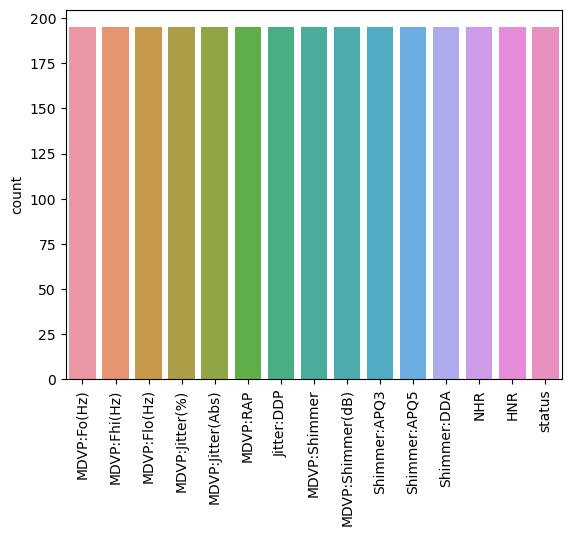

In [14]:
sns.countplot(data=dataset)
plt.xticks(rotation=90)

In [15]:
X = dataset.drop('status', axis=1)
X.head()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:DDA,NHR,HNR
name,,,,,,,,,,,,,,
phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.01109,0.04374,0.426,0.02182,0.03130,0.06545,0.02211,21.033
phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.01394,0.06134,0.626,0.03134,0.04518,0.09403,0.01929,19.085
phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.01633,0.05233,0.482,0.02757,0.03858,0.08270,0.01309,20.651
phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.01505,0.05492,0.517,0.02924,0.04005,0.08771,0.01353,20.644
phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.01966,0.06425,0.584,0.03490,0.04825,0.10470,0.01767,19.649


In [16]:
Y=dataset['status']
Y.head()

name
phon_R01_S01_1    1
phon_R01_S01_2    1
phon_R01_S01_3    1
phon_R01_S01_4    1
phon_R01_S01_5    1
Name: status, dtype: int64

In [17]:
Y.value_counts(normalize=True)

1    0.753846
0    0.246154
Name: status, dtype: float64

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/manifold/_t_sne.py:800: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/manifold/_t_sne.py:810: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  warnings.warn(


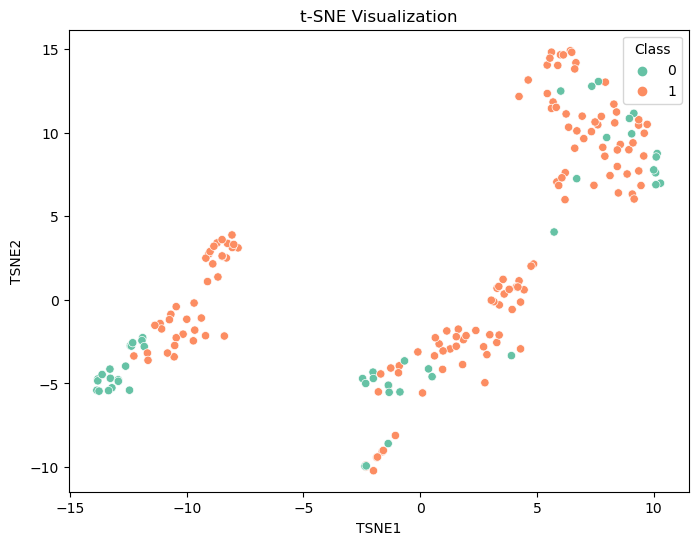

In [18]:
from sklearn.manifold import TSNE

# Apply t-SNE to reduce the dimensions to 2
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

# Create a DataFrame with the t-SNE-transformed data and class labels
tsne_df = pd.DataFrame(data=X_tsne, columns=['TSNE1', 'TSNE2'])
tsne_df['Class'] = Y.values

# Visualize the data based on class using a scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=tsne_df, x='TSNE1', y='TSNE2', hue='Class', palette='Set2')
plt.title('t-SNE Visualization')
plt.show()

In [19]:
from sklearn import model_selection
X_train, X_test, Y_train, Y_test = model_selection.train_test_split(X, Y, test_size = 0.3, random_state = 7)


In [20]:
# print the shape of train and test data
print("X_train shape: ", X_train.shape)
print("y_train shape: ", Y_train.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", Y_test.shape)

X_train shape:  (136, 14)
y_train shape:  (136,)
X_test shape:  (59, 14)
y_test shape:  (59,)


In [21]:
Y

name
phon_R01_S01_1    1
phon_R01_S01_2    1
phon_R01_S01_3    1
phon_R01_S01_4    1
phon_R01_S01_5    1
                 ..
phon_R01_S50_2    0
phon_R01_S50_3    0
phon_R01_S50_4    0
phon_R01_S50_5    0
phon_R01_S50_6    0
Name: status, Length: 195, dtype: int64

In [22]:
# 10-fold cross validation to estimate accuracy (split data into 10 parts; use 9 parts to train and 1 for test)
num_folds = 10
num_instances = len(X_train)
seed = 7
# use the 'accuracy' metric to evaluate models (correct / total)
scoring = 'accuracy'

In [23]:
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier

In [24]:
# algorithms / models
models = []
models.append(('LR', LogisticRegression()))
models.append(('KNN', KNeighborsClassifier()))
models.append(('DT', DecisionTreeClassifier()))
models.append(('GB', GradientBoostingClassifier(n_estimators=10000)))

Scores for each algorithm:
LR 77.96610169491525
0.34093771510603854
[[ 6  6]
 [ 7 40]]
              precision    recall  f1-score   support

           0       0.46      0.50      0.48        12
           1       0.87      0.85      0.86        47

    accuracy                           0.78        59
   macro avg       0.67      0.68      0.67        59
weighted avg       0.79      0.78      0.78        59



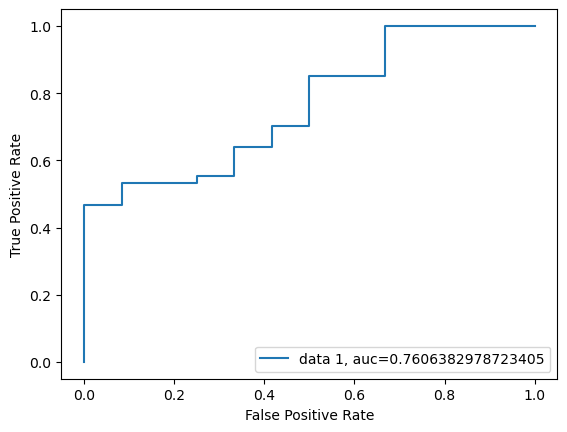


KNN 86.4406779661017
0.5265647117368859
[[ 5  7]
 [ 1 46]]
              precision    recall  f1-score   support

           0       0.83      0.42      0.56        12
           1       0.87      0.98      0.92        47

    accuracy                           0.86        59
   macro avg       0.85      0.70      0.74        59
weighted avg       0.86      0.86      0.85        59



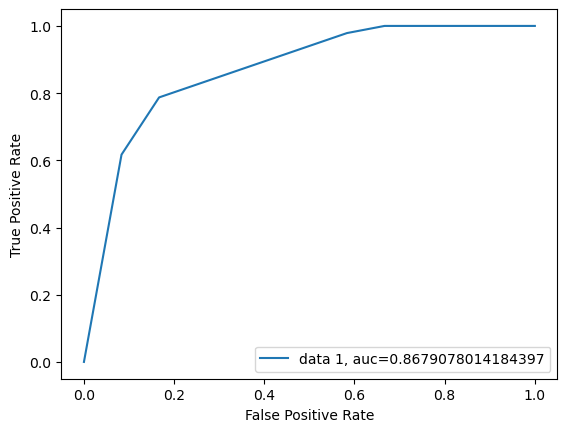


DT 79.66101694915254
0.4110136616980546
[[ 7  5]
 [ 7 40]]
              precision    recall  f1-score   support

           0       0.50      0.58      0.54        12
           1       0.89      0.85      0.87        47

    accuracy                           0.80        59
   macro avg       0.69      0.72      0.70        59
weighted avg       0.81      0.80      0.80        59



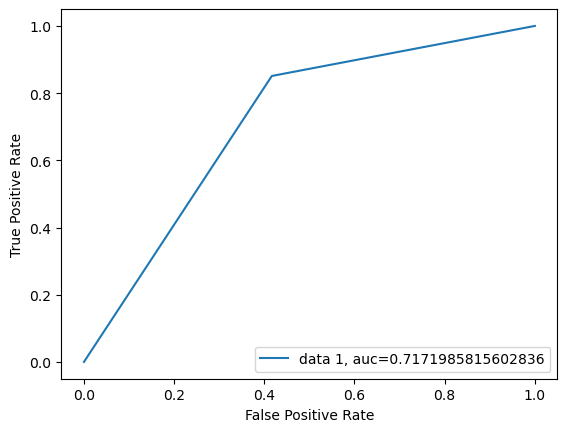


GB 93.22033898305084
0.7818154163240263
[[ 9  3]
 [ 1 46]]
              precision    recall  f1-score   support

           0       0.90      0.75      0.82        12
           1       0.94      0.98      0.96        47

    accuracy                           0.93        59
   macro avg       0.92      0.86      0.89        59
weighted avg       0.93      0.93      0.93        59



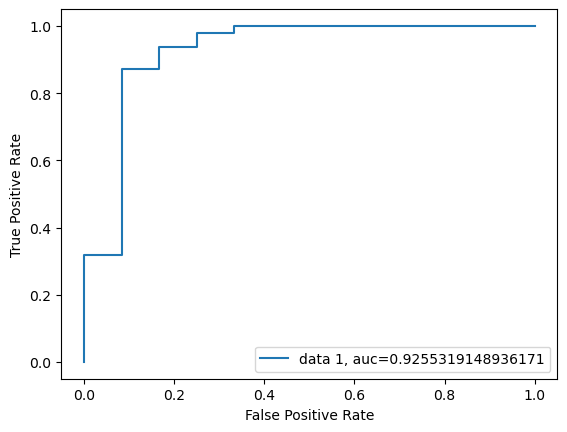

In [25]:
# evaluate each algorithm / model
results = []
names = []
print("Scores for each algorithm:")
for name, model in models:
#     kfold = model_selection.KFold(n_splits = num_folds)
#     cv_results = model_selection.cross_val_score(model, X_train, Y_train, cv = kfold, scoring = scoring)
#     results.append(cv_results)
    names.append(name)
    model.fit(X_train, Y_train)
    predictions = model.predict(X_test)
    print(name, accuracy_score(Y_test, predictions)*100)
    print(matthews_corrcoef(Y_test, predictions))
    print(confusion_matrix(Y_test, predictions))
    print(classification_report(Y_test, predictions))
    y_pred_proba = model.predict_proba(X_test)[::,1]
    fpr, tpr, _ = roc_curve(Y_test,  y_pred_proba)
    auc = roc_auc_score(Y_test, y_pred_proba)
    plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
    plt.ylabel('True Positive Rate')
    plt.xlabel('False Positive Rate')
    plt.legend(loc=4)
    plt.show()
    print()

### XGBoost Classifier

In [26]:
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
cross_val_score(XGBClassifier(), X, Y)

array([0.82051282, 0.76923077, 0.87179487, 0.58974359, 0.66666667])

In [27]:
np.mean(cross_val_score(XGBClassifier(), X, Y, cv=5, scoring='accuracy'))

0.7435897435897436

In [28]:
model = XGBClassifier()
model.fit(X_train, Y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=100, n_jobs=None, num_parallel_tree=None,
              predictor=None, random_state=None, ...)

In [29]:
# make predictions for test data
y_pred = model.predict(X_test)

In [30]:
predictions = [round(value) for value in y_pred]

In [31]:
# evaluate predictions
accuracy = accuracy_score(Y_test, predictions)
print("Accuracy: %.2f%%" % (accuracy * 100.0))

Accuracy: 91.53%


In [32]:
print(matthews_corrcoef(Y_test, predictions))

0.7225294854661686


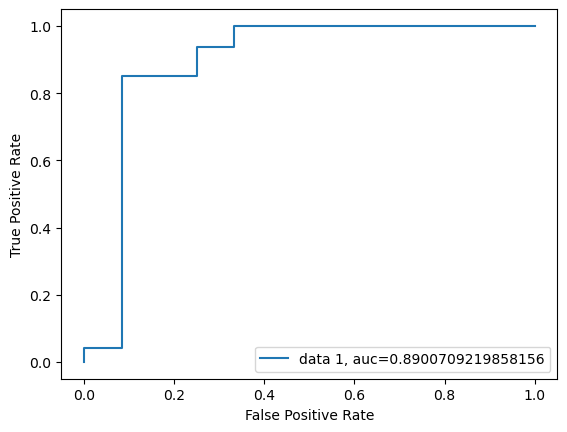

In [33]:
y_pred_proba = model.predict_proba(X_test)[::,1]
fpr, tpr, _ = roc_curve(Y_test,  y_pred_proba)
auc = roc_auc_score(Y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc=4)
plt.show()
print()

### CatBoost Classifier

In [34]:
from catboost import CatBoostClassifier, Pool

In [35]:
catboost_model = CatBoostClassifier(iterations=2,
                           depth=2,
                           learning_rate=1,
                           loss_function='Logloss',
                           verbose=True)

In [36]:
catboost_model.fit(X_train, Y_train)

0:	learn: 0.4361808	total: 58.3ms	remaining: 58.3ms
1:	learn: 0.3807289	total: 58.6ms	remaining: 0us


In [37]:
preds_class = catboost_model.predict(X_test)
preds_proba = catboost_model.predict_proba(X_test)

In [38]:
print(type(preds_proba))

<class 'numpy.ndarray'>


In [39]:
print(catboost_model.get_best_score())

{'learn': {'Logloss': 0.38072894601260915}}


# Part II - Tuning Machine Learning Models

## XGBoost Hyperparameter Tuning

In [45]:
import xgboost as xgb
import sklearn.metrics as metrics
from sklearn.model_selection import GridSearchCV
from xgboost import plot_importance

In [46]:
# A function to create XGBoost models and perform cross-validation

def modelfit(alg, dtrain, predictors,useTrainCV=True, cv_folds=5, early_stopping_rounds=50):
    
    if useTrainCV:
        xgb_param = alg.get_xgb_params()
        xgtrain = xgb.DMatrix(dtrain[predictors].values, label=dtrain['status'].values)
        cvresult = xgb.cv(xgb_param, xgtrain, num_boost_round=alg.get_params()['n_estimators'], nfold=cv_folds,
            metrics='auc', early_stopping_rounds=early_stopping_rounds)
        alg.set_params(n_estimators=cvresult.shape[0])
    
    #Fit the algorithm on the data
    alg.fit(dtrain[predictors], dtrain['status'],eval_metric='auc')
        
    #Predict training set:
    dtrain_predictions = alg.predict(dtrain[predictors])
    dtrain_predprob = alg.predict_proba(dtrain[predictors])[:,1]
        
    #Print model report:
    print ("\nModel Report")
    print ("Accuracy : %.4g" % metrics.accuracy_score(dtrain['status'].values, dtrain_predictions))
    print ("AUC Score (Train): %f" % metrics.roc_auc_score(dtrain['status'], dtrain_predprob))
    
    plot_importance(alg)


Model Report
Accuracy : 0.9949
AUC Score (Train): 0.999858


/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/xgboost/sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


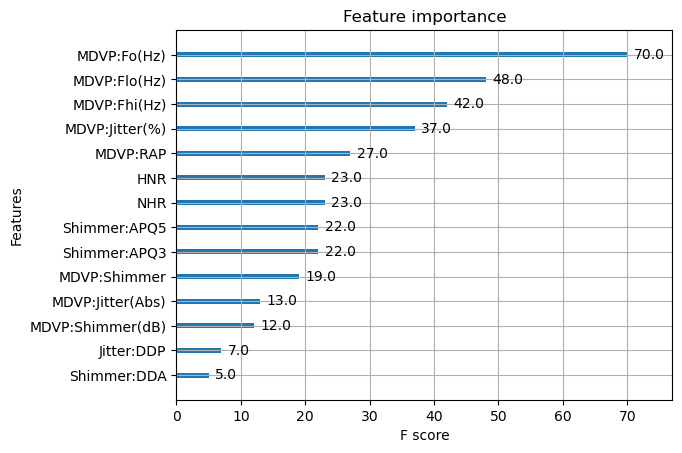

In [47]:
#Choose all predictors except target & IDcols
predictors = [x for x in dataset.columns if x not in ['status']]
xgb1 = XGBClassifier(
 learning_rate =0.1,
 n_estimators=50,
 max_depth=5,
 min_child_weight=1,
 gamma=0,
 subsample=0.8,
 colsample_bytree=0.8,
 objective= 'binary:logistic',
 nthread=4,
 scale_pos_weight=1,
 seed=27)
modelfit(xgb1, dataset, predictors)

GB 98.30508474576271
0.9474014167418394
[[11  1]
 [ 0 47]]
              precision    recall  f1-score   support

           0       1.00      0.92      0.96        12
           1       0.98      1.00      0.99        47

    accuracy                           0.98        59
   macro avg       0.99      0.96      0.97        59
weighted avg       0.98      0.98      0.98        59



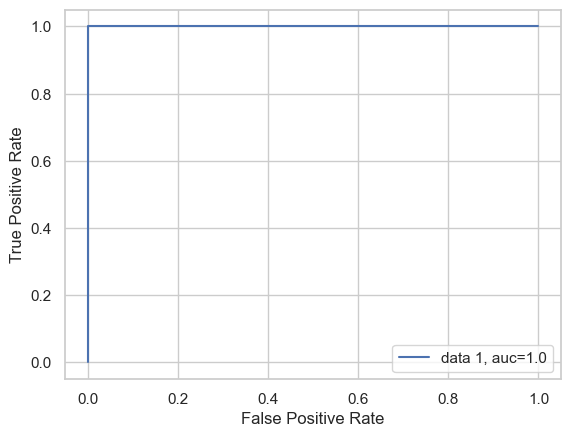

In [102]:
predictions = xgb1.predict(X_test)
print(name, accuracy_score(Y_test, predictions)*100)
print(matthews_corrcoef(Y_test, predictions))
print(confusion_matrix(Y_test, predictions))
print(classification_report(Y_test, predictions))
y_pred_proba = xgb1.predict_proba(X_test)[::,1]
fpr, tpr, _ = roc_curve(Y_test,  y_pred_proba)
auc = roc_auc_score(Y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc=4)
plt.show()

In [48]:
param_test1 = {
 'max_depth':range(3,10,2),
 'min_child_weight':range(1,6,2),
 'n_estimators': range(50, 400, 50)
}
gsearch1 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1,
 gamma=0, subsample=0.8, colsample_bytree=0.8,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1, seed=27), 
 param_grid = param_test1, scoring='roc_auc',n_jobs=4,cv=5)
gsearch1.fit(dataset[predictors],dataset['status'])

GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=0.8,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=0, gpu_id=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=0.1, max_b...
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     n_estimators=100, n_jobs=None, nthread=4,
                                     num_parallel_tree=None, predictor=None, ...),
             n_jobs=4,
             param_grid={'max_depth': range(3, 10, 2),
                         'min_child_weight': range(1, 6, 2),
                         'n_estimators': range(50, 400, 50)},
             scoring='roc_auc')

In [49]:
gsearch1.best_params_

{'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 50}

In [50]:
gsearch1.best_score_

0.7752745849297573

In [51]:
param_test2 = {
 'max_depth':[3,4,5],
 'min_child_weight':[4,5,6]
}
gsearch2 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1,
 gamma=0, subsample=0.8, colsample_bytree=0.8, n_estimators=50,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1, seed=27), 
 param_grid = param_test2, scoring='roc_auc',n_jobs=4,cv=5)
gsearch2.fit(dataset[predictors],dataset['status'])

GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=0.8,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=0, gpu_id=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=0.1, max_bin=None,
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     n_estimators=50, n_jobs=None, nthread=4,
                                     num_parallel_tree=None, predictor=None, ...),
             n_jobs=4,
             param_grid={'max_depth': [3, 4, 5], 'min_child_weight': [4, 5, 6]},
             scoring='roc_auc')

In [52]:
gsearch2.best_params_

{'max_depth': 3, 'min_child_weight': 5}

In [53]:
gsearch2.best_score_

0.7752745849297573

In [54]:
param_test2b = {
    'min_child_weight': [5,6,8,10,12]
}

gsearch2b = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1, max_depth=3,
 gamma=0, subsample=0.8, colsample_bytree=0.8, n_estimators=50,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1, seed=27), 
 param_grid = param_test2b, scoring='roc_auc',n_jobs=4,cv=5)
gsearch2b.fit(dataset[predictors],dataset['status'])

GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=0.8,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=0, gpu_id=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=0.1, max_bin=None,
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=3,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     n_estimators=50, n_jobs=None, nthread=4,
                                     num_parallel_tree=None, predictor=None, ...),
             n_jobs=4, param_grid={'min_child_weight': [5, 6, 8, 10, 12]},
             scoring='roc_auc')

In [55]:
gsearch2b.best_params_

{'min_child_weight': 5}

In [56]:
gsearch2b.best_score_

0.7752745849297573

In [57]:
param_test3 = {
 'gamma':[i/10.0 for i in range(0,5)]
}
gsearch3 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1, n_estimators=50, max_depth=3,
 min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1,seed=27), 
 param_grid = param_test3, scoring='roc_auc',n_jobs=4, cv=5)
gsearch3.fit(dataset[predictors],dataset['status'])
gsearch3.best_params_, gsearch3.best_score_

({'gamma': 0.0}, 0.7752745849297573)


Model Report
Accuracy : 0.9179
AUC Score (Train): 0.972222


/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/xgboost/sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


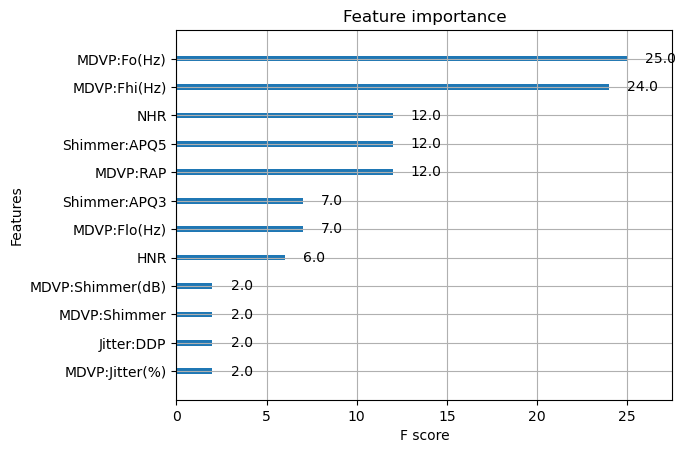

In [58]:
# Recaliberation

xgb2 = XGBClassifier(
 learning_rate =0.1,
 n_estimators=50,
 max_depth=3,
 min_child_weight=5,
 gamma=0,
 subsample=0.8,
 colsample_bytree=0.8,
 objective= 'binary:logistic',
 nthread=4,
 scale_pos_weight=1,
 seed=27)
modelfit(xgb2, dataset, predictors)

In [59]:
param_test4 = {
 'subsample':[i/10.0 for i in range(6,10)],
 'colsample_bytree':[i/10.0 for i in range(6,10)]
}

gsearch4 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1, n_estimators=50, max_depth=3,
 min_child_weight=5, gamma=0,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1,seed=27), 
 param_grid = param_test4, scoring='roc_auc',n_jobs=4, cv=5)
gsearch4.fit(dataset[predictors],dataset['status'])
gsearch4.best_params_, gsearch4.best_score_

({'colsample_bytree': 0.6, 'subsample': 0.8}, 0.7818007662835249)

In [61]:
param_test6 = {
 'reg_alpha':[1e-5, 1e-2, 0.1, 1, 100]
}

gsearch6 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1, n_estimators=50, max_depth=3,
 min_child_weight=5, gamma=0, subsample=0.8, colsample_bytree=0.6,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1,seed=27), 
 param_grid = param_test6, scoring='roc_auc',n_jobs=4, cv=5)
gsearch6.fit(dataset[predictors],dataset['status'])
gsearch6.best_params_, gsearch6.best_score_

({'reg_alpha': 1}, 0.7870242656449553)

In [63]:
param_test7 = {
 'reg_alpha':[0, 0.001, 0.005, 0.01, 0.05, 1, 1.5]
}

gsearch7 = GridSearchCV(estimator = XGBClassifier( learning_rate =0.1, n_estimators=50, max_depth=3,
 min_child_weight=5, gamma=0, subsample=0.8, colsample_bytree=0.6,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1,seed=27), 
 param_grid = param_test7, scoring='roc_auc',n_jobs=4, cv=5)
gsearch7.fit(dataset[predictors],dataset['status'])
gsearch7.best_params_, gsearch7.best_score_

({'reg_alpha': 1.5}, 0.787816091954023)


Model Report
Accuracy : 0.9179
AUC Score (Train): 0.963931


/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/xgboost/sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


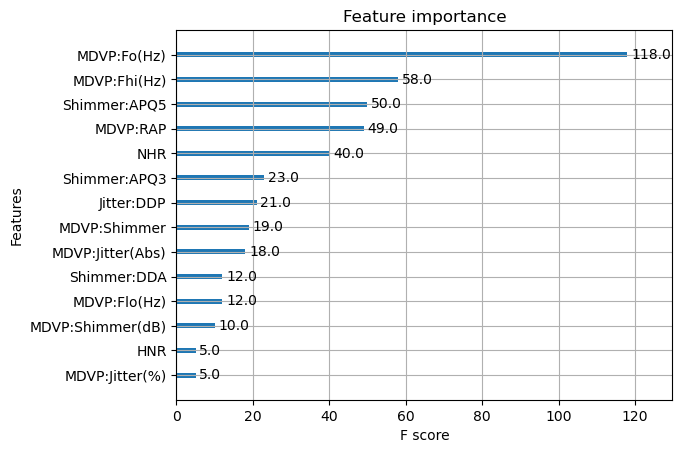

In [64]:
xgb3 = XGBClassifier(
 learning_rate =0.01,
 n_estimators=1000,
 max_depth=3,
 min_child_weight=5,
 gamma=0,
 subsample=0.8,
 colsample_bytree=0.6,
 objective= 'binary:logistic',
 nthread=4,
 scale_pos_weight=1,
 seed=27)
modelfit(xgb3, dataset, predictors)

GB 93.22033898305084
0.7838233761296739
[[ 8  4]
 [ 0 47]]
              precision    recall  f1-score   support

           0       1.00      0.67      0.80        12
           1       0.92      1.00      0.96        47

    accuracy                           0.93        59
   macro avg       0.96      0.83      0.88        59
weighted avg       0.94      0.93      0.93        59



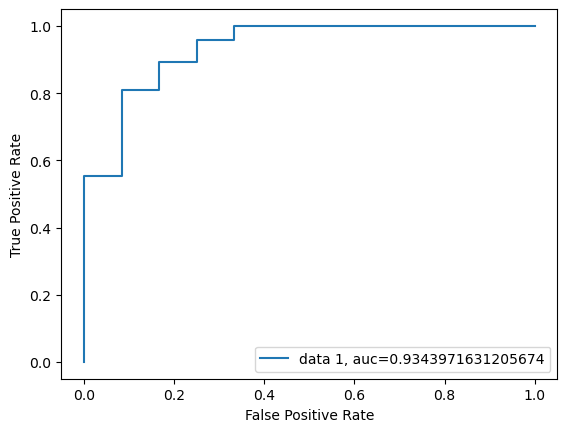

In [65]:
predictions = xgb3.predict(X_test)
print(name, accuracy_score(Y_test, predictions)*100)
print(matthews_corrcoef(Y_test, predictions))
print(confusion_matrix(Y_test, predictions))
print(classification_report(Y_test, predictions))
y_pred_proba = xgb3.predict_proba(X_test)[::,1]
fpr, tpr, _ = roc_curve(Y_test,  y_pred_proba)
auc = roc_auc_score(Y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc=4)
plt.show()

In [66]:
test_data = pd.read_csv ('mdvp_voice_dataset.csv', index_col=['name']) 

test_data.head()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:DDA,NHR,HNR
name,,,,,,,,,,,,,,
MSA1a1,126.624,209.756,67.130,4.43800,0.000338,2.77300,8.15000,20.57900,1.712,10.94600,11.13000,32.83800,0.43800,2.283
MSA2a1,130.192,152.292,66.592,1.82300,0.000132,1.33000,2.96800,17.96500,1.421,8.58500,10.54300,25.75600,0.18000,5.556
MSA3a1,255.480,374.196,87.803,4.05000,0.000146,1.17300,7.62300,17.13800,1.084,7.02400,7.68100,21.07300,0.48100,2.079
MSA4a1,174.188,230.978,94.261,0.00459,0.000030,0.00263,0.00790,0.04087,0.405,0.02336,0.02498,0.07008,0.02764,19.517
MSA5a1,149.818,163.417,144.786,0.00336,0.000020,0.00174,0.00521,0.02145,0.198,0.01155,0.01341,0.03464,0.00595,23.008


In [67]:
real_predictions = xgb3.predict(test_data)

In [68]:
real_predictions

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0])

## Logistic Regression Parameter Tuning

In [69]:
from sklearn.linear_model import LogisticRegression
logReg = LogisticRegression()

In [70]:
param_grid = [    
    {'penalty' : ['l1', 'l2', 'elasticnet', 'none'],
    'C' : np.logspace(-4, 4, 20),
    'solver' : ['lbfgs','newton-cg','liblinear','sag','saga'],
    'max_iter' : [100, 1000,2500, 5000]
    }
]

In [71]:
clf = GridSearchCV(logReg, param_grid = param_grid, cv = 3, verbose=True, n_jobs=-1)

In [72]:
best_clf = clf.fit(X,Y)

Fitting 3 folds for each of 1600 candidates, totalling 4800 fits


/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/sit

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/scipy/optimize/_linesearch.py:456: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/scipy/optimize/_linesearch.py:305: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio param

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/scipy/optimize/_linesearch.py:456: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/scipy/optimize/_linesearch.py:305: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not con

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/sit

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/utils/optimize.py:210: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/scipy/optimize/_linesearch.py:456: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/scipy/optimize/_linesearch.py:305: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio paramet

... (22 outputs left out)

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/sit

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/scipy/optimize/_linesearch.py:456: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/scipy/optimize/_linesearch.py:305: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio param

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/scipy/optimize/_linesearch.py:456: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/scipy/optimize/_linesearch.py:305: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio param

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/model_selection/_search.py:953: UserWarning: One or more of the test scores are non-finite: [       nan        nan 0.24615385 ...        nan 0.73846154 0.73846154]
  warnings.warn(


In [73]:
best_clf.best_estimator_

LogisticRegression(C=0.004832930238571752)

In [74]:
best_clf.best_score_

0.8256410256410257

In [75]:
print (f'Accuracy - : {best_clf.score(X,Y):.3f}')

Accuracy - : 0.836


In [76]:
from sklearn.model_selection import RepeatedStratifiedKFold

In [77]:
# define models and parameters
model = LogisticRegression(max_iter = 10000)
solvers = ['newton-cg', 'lbfgs', 'liblinear']
penalty = ['l2']
c_values = [100, 10, 1.0, 0.1, 0.01]
# define grid search
grid = dict(solver=solvers,penalty=penalty,C=c_values)
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, cv=cv, scoring='accuracy',error_score=0)
grid_result = grid_search.fit(X, Y)
# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Best: 0.831930 using {'C': 1.0, 'penalty': 'l2', 'solver': 'liblinear'}
0.801491 (0.095614) with: {'C': 100, 'penalty': 'l2', 'solver': 'newton-cg'}
0.806667 (0.094565) with: {'C': 100, 'penalty': 'l2', 'solver': 'lbfgs'}
0.803246 (0.094892) with: {'C': 100, 'penalty': 'l2', 'solver': 'liblinear'}
0.805000 (0.097030) with: {'C': 10, 'penalty': 'l2', 'solver': 'newton-cg'}
0.805000 (0.097030) with: {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}
0.809825 (0.092904) with: {'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}
0.810175 (0.099497) with: {'C': 1.0, 'penalty': 'l2', 'solver': 'newton-cg'}
0.810175 (0.099497) with: {'C': 1.0, 'penalty': 'l2', 'solver': 'lbfgs'}
0.831930 (0.077277) with: {'C': 1.0, 'penalty': 'l2', 'solver': 'liblinear'}
0.811842 (0.098046) with: {'C': 0.1, 'penalty': 'l2', 'solver': 'newton-cg'}
0.811842 (0.098046) with: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
0.760877 (0.028608) with: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
0.820175 (0.092424) wit

LR 86.4406779661017
0.5378362527698295
[[ 6  6]
 [ 2 45]]
              precision    recall  f1-score   support

           0       0.75      0.50      0.60        12
           1       0.88      0.96      0.92        47

    accuracy                           0.86        59
   macro avg       0.82      0.73      0.76        59
weighted avg       0.86      0.86      0.85        59



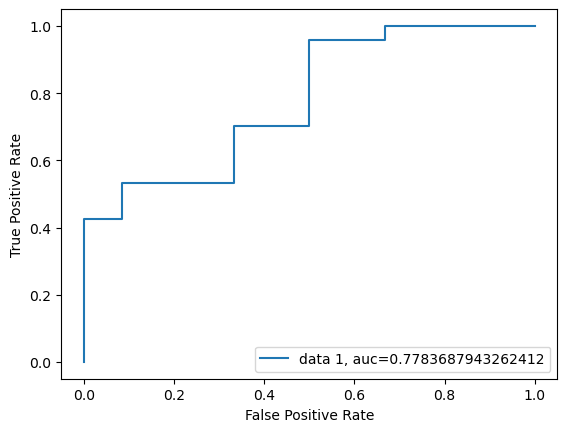

In [78]:
predictions = best_clf.predict(X_test)
print("LR", accuracy_score(Y_test, predictions)*100)
print(matthews_corrcoef(Y_test, predictions))
print(confusion_matrix(Y_test, predictions))
print(classification_report(Y_test, predictions))
y_pred_proba = best_clf.predict_proba(X_test)[::,1]
fpr, tpr, _ = roc_curve(Y_test,  y_pred_proba)
auc = roc_auc_score(Y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc=4)
plt.show()

## KNN Hyperparameter Tuning

In [79]:
train_score = {}
test_score = {}
n_neighbors = np.arange(2, 30, 1)
for neighbor in n_neighbors:
    knn = KNeighborsClassifier(n_neighbors=neighbor)
    knn.fit(X_train, Y_train)
    train_score[neighbor]=knn.score(X_train, Y_train)
    test_score[neighbor]=knn.score(X_test, Y_test)

In [80]:
sns.set(style="whitegrid", color_codes=True)
import itertools

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = 3*cm.max()/4
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

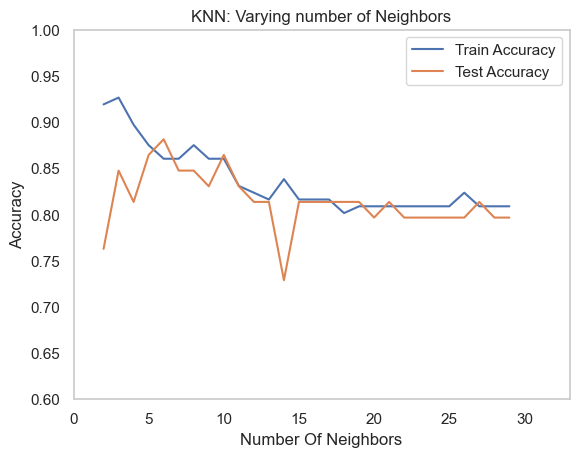

In [81]:
plt.plot(n_neighbors, train_score.values(), label="Train Accuracy")
plt.plot(n_neighbors, test_score.values(), label="Test Accuracy")
plt.xlabel("Number Of Neighbors")
plt.ylabel("Accuracy")
plt.title("KNN: Varying number of Neighbors")
plt.legend()
plt.xlim(0, 33)
plt.ylim(0.60, 1)
plt.grid()
plt.show()

In [82]:
for key, value in test_score.items():
    if value==max(test_score.values()):
        print(key)

6


In [83]:
# Using GridSearchCV to find optimum parameters
from sklearn.model_selection import KFold

kf=KFold(n_splits=5,shuffle=True,random_state=42)
parameter={'n_neighbors': np.arange(2, 30, 1)}
knn=KNeighborsClassifier()
knn_cv=GridSearchCV(knn, param_grid=parameter, cv=kf, verbose=1)
knn_cv.fit(X_train, Y_train)
print(knn_cv.best_params_)

Fitting 5 folds for each of 28 candidates, totalling 140 fits
{'n_neighbors': 3}


In [84]:
knn=KNeighborsClassifier(n_neighbors=23)
knn.fit(X_train, Y_train)
y_pred=knn.predict(X_test)
print(accuracy_score(Y_test, y_pred))

0.7966101694915254


In [85]:
knn = KNeighborsClassifier(n_neighbors=6)

In [86]:
knn.fit(X_train, Y_train)

KNeighborsClassifier(n_neighbors=6)

In [87]:
y_pred = knn.predict(X_test)
y_pred[0:10]

array([0, 1, 1, 1, 1, 1, 1, 0, 1, 1])

In [88]:
knn.predict_proba(X_test)[0:10]

array([[0.5       , 0.5       ],
       [0.33333333, 0.66666667],
       [0.        , 1.        ],
       [0.33333333, 0.66666667],
       [0.16666667, 0.83333333],
       [0.        , 1.        ],
       [0.        , 1.        ],
       [0.66666667, 0.33333333],
       [0.        , 1.        ],
       [0.        , 1.        ]])

In [89]:
print("\nClassification Report:\n", classification_report(Y_test, y_pred))
print("\nAccuracy Score:", accuracy_score(Y_test, y_pred))


Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.58      0.67        12
           1       0.90      0.96      0.93        47

    accuracy                           0.88        59
   macro avg       0.84      0.77      0.80        59
weighted avg       0.88      0.88      0.87        59


Accuracy Score: 0.8813559322033898


KNN 88.13559322033898
0.6054161897450039
[[ 7  5]
 [ 2 45]]
              precision    recall  f1-score   support

           0       0.78      0.58      0.67        12
           1       0.90      0.96      0.93        47

    accuracy                           0.88        59
   macro avg       0.84      0.77      0.80        59
weighted avg       0.88      0.88      0.87        59



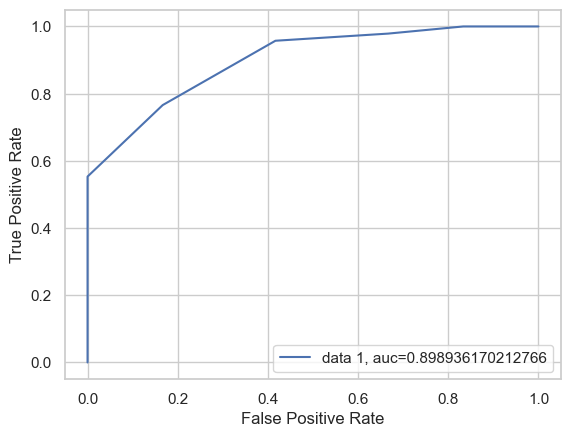

In [90]:
predictions = knn.predict(X_test)
print("KNN", accuracy_score(Y_test, predictions)*100)
print(matthews_corrcoef(Y_test, predictions))
print(confusion_matrix(Y_test, predictions))
print(classification_report(Y_test, predictions))
y_pred_proba = knn.predict_proba(X_test)[::,1]
fpr, tpr, _ = roc_curve(Y_test,  y_pred_proba)
auc = roc_auc_score(Y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc=4)
plt.show()

## Decision Tree Hyperparameter Tuning

In [91]:
dt = DecisionTreeClassifier()

In [92]:
param_grid = {
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt', 'log2'],
    'criterion': ['gini', 'entropy']
}

In [93]:
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, cv=5, n_jobs=-1, verbose=2)
grid_search.fit(X_train, Y_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/tree/_classes.py:298: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'`.
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/tree/_classes.py:298: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'`.
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/tree/_classes.py:298: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'`.
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/tree/_classes.py:298: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly 

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/tree/_classes.py:298: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'`.
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/tree/_classes.py:298: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'`.
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/tree/_classes.py:298: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'`.
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/tree/_classes.py:298: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly 

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/tree/_classes.py:298: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'`.
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/tree/_classes.py:298: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'`.
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/tree/_classes.py:298: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'`.
  warnings.warn(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/tree/_classes.py:298: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly 

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [None, 10, 20, 30],
                         'max_features': ['auto', 'sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             verbose=2)

In [94]:
best_dt = grid_search.best_estimator_
y_pred = best_dt.predict(X_test)

In [95]:
grid_search.best_score_

0.8746031746031747

In [96]:
grid_search.best_params_

{'criterion': 'gini',
 'max_depth': 10,
 'max_features': 'sqrt',
 'min_samples_leaf': 1,
 'min_samples_split': 5}

In [97]:
param_grid_2 = {
    'max_depth': [25, 30, 35],
    'min_samples_split': [1, 5, 10, 15],
    'min_samples_leaf': [0, 1, 2, 4],
}

In [98]:
grid_search.best_estimator_

DecisionTreeClassifier(max_depth=10, max_features='sqrt', min_samples_split=5)

In [99]:
print(classification_report(Y_test, y_pred))
print(confusion_matrix(Y_test, y_pred))

              precision    recall  f1-score   support

           0       0.57      0.67      0.62        12
           1       0.91      0.87      0.89        47

    accuracy                           0.83        59
   macro avg       0.74      0.77      0.75        59
weighted avg       0.84      0.83      0.84        59

[[ 8  4]
 [ 6 41]]


In [100]:
print("DT Accuracy Score: ", accuracy_score(Y_test, y_pred))

DT Accuracy Score:  0.8305084745762712


DT 83.05084745762711
0.5099924618620759
[[ 8  4]
 [ 6 41]]
              precision    recall  f1-score   support

           0       0.57      0.67      0.62        12
           1       0.91      0.87      0.89        47

    accuracy                           0.83        59
   macro avg       0.74      0.77      0.75        59
weighted avg       0.84      0.83      0.84        59



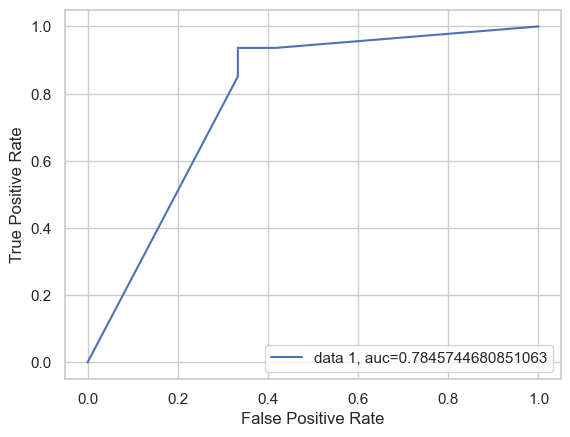

[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=5; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=log2, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=log2, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=log2, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None,

[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=2, min_samples_split=10; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=2, min_samples_split=10; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=4, min_samples_split=5; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=4, min_samples_split=5; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5; total time=   0.0s
[CV] END criterion=gini, max_depth=Non

[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=5; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=4, min_samples_split=5; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=4, min_samples_split=5; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=sqrt, min_samples_leaf=4, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None,

[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=10; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=2, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=2, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=2, min_samples_split=5; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=2, min_samples_split=10; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=4, min_samples_split=2; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=auto, min_samples_leaf=4, min_samples_split=5; total time=   0.0s
[CV] END criterion=gini, max_depth=Non

In [101]:
predictions = grid_search.predict(X_test)
print("DT", accuracy_score(Y_test, predictions)*100)
print(matthews_corrcoef(Y_test, predictions))
print(confusion_matrix(Y_test, predictions))
print(classification_report(Y_test, predictions))
y_pred_proba = grid_search.predict_proba(X_test)[::,1]
fpr, tpr, _ = roc_curve(Y_test,  y_pred_proba)
auc = roc_auc_score(Y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc=4)
plt.show()